# Graph — Klasifikasi Graf Utuh (satu label per graf: molekul, jaringan, struktur)
**Kapan dipakai:** data berisi banyak graf kecil dan **tiap graf** punya satu label
(molekul beracun atau tidak, jaringan normal atau diserang).

**Idenya:** tiap graf diubah menjadi satu baris feature, lalu model tabular biasa:
statistik graf, jumlah tiap label simpul/sisi, dan hash Weisfeiler-Lehman (WL) = pola
tetangga sampai beberapa langkah.

**Langkah:**
1. Baca format TU Dataset, susun satu graf networkx per molekul.
2. Hitung feature tiap graf.
3. Evaluasi dengan CV 10-fold (data kecil), simpan prediksi out-of-fold.

**Data demo:** MUTAG (188 molekul, label = mutagenik atau tidak). File TU Dataset:
`*_A.txt` (sisi), `*_graph_indicator.txt` (simpul milik graf ke berapa),
`*_graph_labels.txt`, `*_node_labels.txt`, `*_edge_labels.txt`.

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/graph/MUTAG"   # GANTI saat lomba
NAME = "MUTAG"                                  # awalan nama file TU Dataset
EDGES_TXT = f"{DATA_FOLDER}/{NAME}_A.txt"
GRAPH_INDICATOR_TXT = f"{DATA_FOLDER}/{NAME}_graph_indicator.txt"
NODE_LABELS_TXT = f"{DATA_FOLDER}/{NAME}_node_labels.txt"
EDGE_LABELS_TXT = f"{DATA_FOLDER}/{NAME}_edge_labels.txt"
GRAPH_LABELS_TXT = f"{DATA_FOLDER}/{NAME}_graph_labels.txt"

WL_ITERATIONS = 3       # langkah Weisfeiler-Lehman (jangkauan tetangga)
MIN_GRAPHS = 3          # pola WL dipakai bila muncul di minimal 3 graf
SEED = 42

## Baca data
Tiap file = satu kolom angka tanpa header. Nomor simpul dan graf di file mulai dari 1.

In [3]:
edges = pd.read_csv(EDGES_TXT, header=None, names=["a", "b"])
graph_of_node = pd.read_csv(GRAPH_INDICATOR_TXT, header=None)[0].to_numpy()
node_labels = pd.read_csv(NODE_LABELS_TXT, header=None)[0].to_numpy()
edge_labels = pd.read_csv(EDGE_LABELS_TXT, header=None)[0].to_numpy()
y = pd.read_csv(GRAPH_LABELS_TXT, header=None)[0]
N_GRAPHS = len(y)
print("graf:", N_GRAPHS, "| simpul:", len(graph_of_node), "| sisi (2 arah):", len(edges))
print(y.value_counts())

graf: 188 | simpul: 3371 | sisi (2 arah): 7442
0
 1    125
-1     63
Name: count, dtype: int64


## Susun graf networkx
Simpul ke-k masuk ke graf nomor `graph_of_node[k - 1]`. Sisi masuk ke graf milik simpul asalnya.

simpul per graf:
count    188.000000
mean      17.930851
std        4.587883
min       10.000000
25%       14.000000
50%       17.500000
75%       22.000000
max       28.000000
dtype: float64


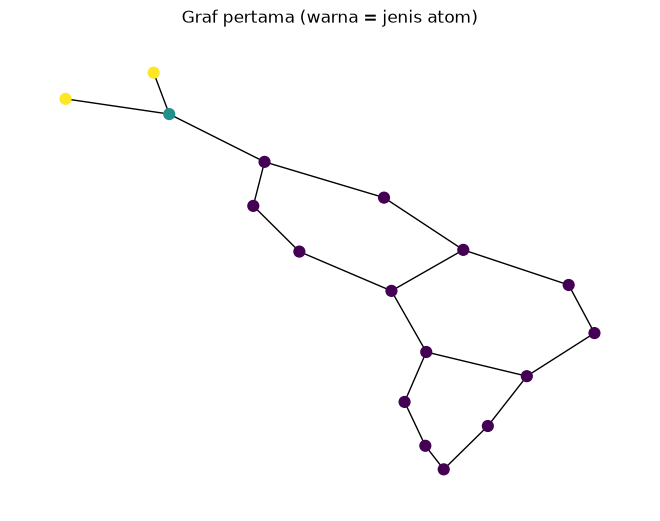

In [4]:
graphs = []
for _ in range(N_GRAPHS):
    graphs.append(nx.Graph())
for node in range(1, len(graph_of_node) + 1):
    graph_number = graph_of_node[node - 1]
    graphs[graph_number - 1].add_node(node, label=str(node_labels[node - 1]))
for node_a, node_b, edge_type in zip(edges["a"], edges["b"], edge_labels):
    graph_number = graph_of_node[node_a - 1]
    graphs[graph_number - 1].add_edge(node_a, node_b, kind=edge_type)

sizes = []
for graph in graphs:
    sizes.append(graph.number_of_nodes())
sizes = pd.Series(sizes)
print("simpul per graf:")
print(sizes.describe())

first_colors = []
for _, label in graphs[0].nodes(data="label"):
    first_colors.append(int(label))
nx.draw(graphs[0], node_size=60, node_color=first_colors)
plt.title("Graf pertama (warna = jenis atom)")
plt.show()

## Langkah 2a — feature statistik per graf

In [5]:
def graph_statistics(graph):
    degrees = []
    for _, degree in graph.degree():
        degrees.append(degree)
    row = {}
    row["n_nodes"] = graph.number_of_nodes()
    row["n_edges"] = graph.number_of_edges()
    row["density"] = nx.density(graph)
    row["mean_degree"] = np.mean(degrees)
    row["max_degree"] = max(degrees)
    row["n_cycles"] = len(nx.cycle_basis(graph))
    row["diameter"] = -1                     # -1 = graf tidak tersambung semua
    if nx.is_connected(graph):
        row["diameter"] = nx.diameter(graph)
    row["clustering"] = nx.average_clustering(graph)
    for _, label in graph.nodes(data="label"):
        row[f"node_{label}"] = row.get(f"node_{label}", 0) + 1     # hitung tiap jenis simpul
    for _, _, kind in graph.edges(data="kind"):
        row[f"edge_{kind}"] = row.get(f"edge_{kind}", 0) + 1       # hitung tiap jenis sisi
    return row


# coba pada graf pertama
print(graph_statistics(graphs[0]))

{'n_nodes': 17, 'n_edges': 19, 'density': 0.13970588235294118, 'mean_degree': np.float64(2.235294117647059), 'max_degree': 3, 'n_cycles': 3, 'diameter': 9, 'clustering': 0.0, 'node_0': 14, 'node_1': 1, 'node_2': 2, 'edge_0': 16, 'edge_1': 2, 'edge_2': 1}


## Langkah 2b — feature Weisfeiler-Lehman
Tiap simpul diberi kode (hash) dari label dirinya + label tetangga sampai `WL_ITERATIONS`
langkah. Feature = berapa kali tiap kode muncul di graf itu.

In [6]:
def wl_counts(graph):
    hashes_per_node = nx.weisfeiler_lehman_subgraph_hashes(graph, node_attr="label",
                                                           iterations=WL_ITERATIONS)
    all_hashes = []
    for node_hashes in hashes_per_node.values():
        all_hashes.extend(node_hashes)
    return Counter(all_hashes)


# coba pada graf pertama: 3 pola paling sering
print(wl_counts(graphs[0]).most_common(3))

[('4ab694b72e4aaa81004c5c189c7fb177', 9), ('90fe7eb4760eca7cd60124eff86334ff', 5), ('0d10b968ef18c9f692175dafff56ef65', 4)]


In [7]:
statistic_rows = []
wl_rows = []
for graph in graphs:
    statistic_rows.append(graph_statistics(graph))
    wl_rows.append(wl_counts(graph))
statistics = pd.DataFrame(statistic_rows).fillna(0)
wl = pd.DataFrame(wl_rows).fillna(0)
graphs_with_pattern = (wl > 0).sum()           # pola muncul di berapa graf
wl = wl.loc[:, graphs_with_pattern >= MIN_GRAPHS]
print("feature statistik:", statistics.shape[1], "| feature WL:", wl.shape[1])

feature statistik: 19 | feature WL: 259


## Pilih feature (satu baris aktif)

In [8]:
X = pd.concat([statistics, wl], axis=1)
# X = statistics                   # tanpa WL
# X = wl                           # WL saja

## Langkah 3 — model
Pilih SATU model: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.

In [9]:
model = RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1)
# model = ExtraTreesClassifier(n_estimators=500, random_state=SEED, n_jobs=-1)
# model = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000))
# model = make_pipeline(StandardScaler(), SVC(C=1.0))
# model = LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=7,
#                        min_child_samples=5, random_state=SEED, verbose=-1)

## Evaluasi: prediksi out-of-fold (CV 10-fold, karena data kecil)
Tiap graf ditebak oleh model yang tidak pernah melihat graf itu saat latih.

In [10]:
folds = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
oof_predictions = cross_val_predict(model, X, y, cv=folds)
print("Akurasi CV:", round(accuracy_score(y, oof_predictions), 4))
print("F1 macro CV:", round(f1_score(y, oof_predictions, average="macro"), 4))
print(classification_report(y, oof_predictions))

Akurasi CV: 0.883
F1 macro CV: 0.8687
              precision    recall  f1-score   support

          -1       0.83      0.83      0.83        63
           1       0.91      0.91      0.91       125

    accuracy                           0.88       188
   macro avg       0.87      0.87      0.87       188
weighted avg       0.88      0.88      0.88       188



## Simpan prediksi out-of-fold per graf
Saat lomba ada graf test: `model.fit(X, y)` lalu `model.predict(X_test)` dengan pola
submission biasa.

In [11]:
submission = pd.DataFrame()
submission["graph"] = np.arange(1, N_GRAPHS + 1)
submission["label"] = oof_predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,graph,label
0,1,1
1,2,-1
2,3,-1
3,4,1
4,5,-1
